### Gas Bottle Baseline Detection

Runs pretrained YOLO11n (COCO) on the local LGP cylinder images and shows what the generic model actually detects.

- Load a pretrained YOLO model in Python
- Run inference on the local image set
- Save annotated examples to disk and display them inline
- Show why the pretrained model cannot reliably detect gas cylinders

Input: `data/all_images/` — local LGP cylinder images
Output: annotated images saved to `results/gas_bottle_baseline/annotated/`, summary printed at the end

In [7]:
from pathlib import Path
from collections import Counter
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

device = 0 if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

PyTorch: 2.14.1+cpu
CUDA available: False
Using device: cpu


### Input images

Local LGP cylinder images live in `data/all_images/`.

In [8]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

IMAGE_DIR = ROOT / "data" / "all_images"
OUTPUT_DIR = ROOT / "results" / "gas_bottle_baseline"
ANNOTATED_DIR = OUTPUT_DIR / "annotated"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTS
)

print(f"Image directory: {IMAGE_DIR.relative_to(ROOT)}")
print(f"Image directory exists: {IMAGE_DIR.exists()}")
print(f"Found {len(image_paths)} images")
print(f"Annotated output: {ANNOTATED_DIR.relative_to(ROOT)}")

if len(image_paths) == 0:
    raise FileNotFoundError(
        f"No images found under {IMAGE_DIR}. Check the folder and file extensions."
    )

for p in image_paths[:5]:
    print(f"  - {p.relative_to(ROOT)}")

Image directory: data\all_images
Image directory exists: True
Found 321 images
Annotated output: results\gas_bottle_baseline\annotated
  - data\all_images\20250326_110923.jpg
  - data\all_images\20250326_112218.jpg
  - data\all_images\20250326_130133.jpg
  - data\all_images\20250326_130204.jpg
  - data\all_images\20250326_130347.jpg


### Load pretrained model

`yolo11n.pt` is COCO-pretrained: 80 generic classes, no gas-cylinder class.

In [9]:
model = YOLO("yolo11n.pt")

coco_classes = model.names
has_cylinder_class = any("cylinder" in str(v).lower() for v in coco_classes.values())

print(f"Model classes: {len(coco_classes)}")
print(f"Has explicit 'cylinder' class: {has_cylinder_class}")
print(f"Sample classes: {list(coco_classes.values())[:15]}...")

Model classes: 80
Has explicit 'cylinder' class: False
Sample classes: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird']...


## Run inference on all images

At confidence 0.25, record the number of detections, the classes found, and the highest confidence per image.

In [10]:
records = []

for img_path in image_paths:
    results = model.predict(
        source=str(img_path),
        conf=0.25,
        device=device,
        verbose=False,
    )

    result = results[0]
    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        records.append({
            "image": img_path.name,
            "n_detections": 0,
            "classes": "",
            "max_conf": 0.0,
        })
        continue

    class_ids = boxes.cls.cpu().numpy().astype(int)
    confs = boxes.conf.cpu().numpy()
    class_names = [coco_classes[i] for i in class_ids]
    unique_classes = sorted(set(class_names))

    records.append({
        "image": img_path.name,
        "n_detections": len(boxes),
        "classes": ";".join(unique_classes),
        "max_conf": float(confs.max()),
    })

df = pd.DataFrame(records)
print(f"Processed {len(df)} images")
df.head()

Processed 321 images


,image,n_detections,classes,max_conf
0,20250326_110923.jpg,0,,0.000000
1,20250326_112218.jpg,2,person;vase,0.825279
2,20250326_130133.jpg,1,fire hydrant,0.426958
3,20250326_130204.jpg,1,fire hydrant,0.661733
4,20250326_130347.jpg,1,fire hydrant,0.880458


### Baseline statistics

Total images, images with at least one detection, total detections, and class distribution.

In [11]:
total_images = len(df)
images_with_detections = int((df["n_detections"] > 0).sum())
total_detections = int(df["n_detections"].sum())

all_classes = []
for c in df["classes"]:
    if c:
        all_classes.extend(c.split(";"))

class_counts = Counter(all_classes)

print("=" * 50)
print("BASELINE DETECTION STATISTICS")
print("=" * 50)
print(f"Total images:                {total_images}")
print(f"Images with >=1 detection:   {images_with_detections} ({images_with_detections/total_images*100:.1f}%)")
print(f"Images with no detection:    {total_images - images_with_detections}")
print(f"Total detections:            {total_detections}")
print()
print("Detected classes (all occurrences):")
for cls, count in class_counts.most_common():
    print(f"  {cls}: {count}")

BASELINE DETECTION STATISTICS
Total images:                321
Images with >=1 detection:   247 (76.9%)
Images with no detection:    74
Total detections:            454

Detected classes (all occurrences):
  vase: 128
  person: 97
  chair: 32
  bottle: 30
  fire hydrant: 18
  cup: 14
  cake: 12
  wine glass: 9
  toilet: 5
  spoon: 4
  car: 4
  bowl: 4
  keyboard: 3
  bird: 2
  knife: 1
  orange: 1
  donut: 1
  suitcase: 1
  parking meter: 1
  bench: 1


### Annotated examples

Five images are chosen: some where the model detected something, some where it detected nothing.

For each one:
- the annotated image is saved under `results/gas_bottle_baseline/annotated/`
- the same image is displayed inline, so you see the model's boxes without leaving the notebook

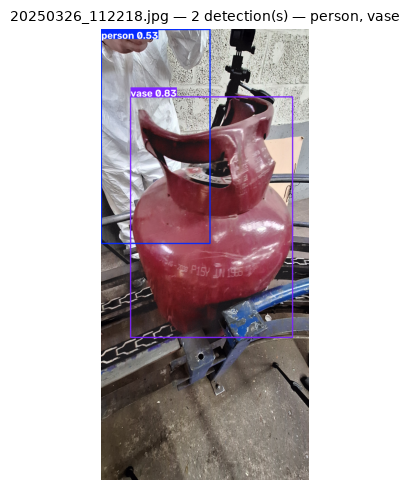

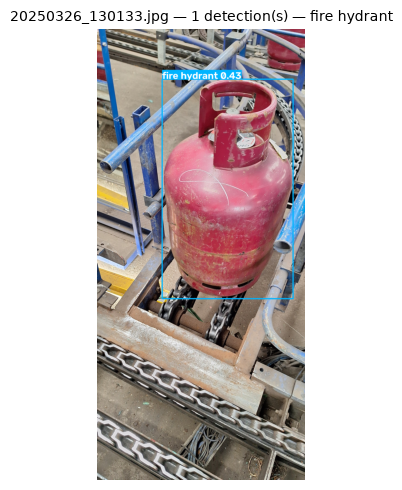

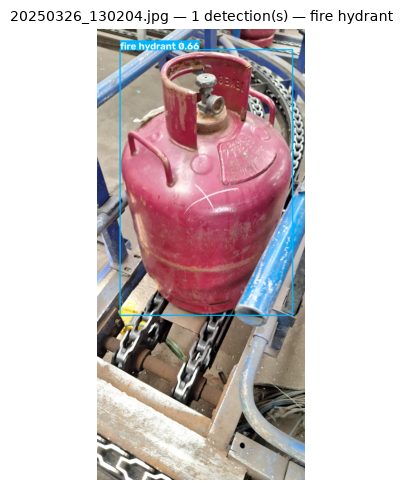

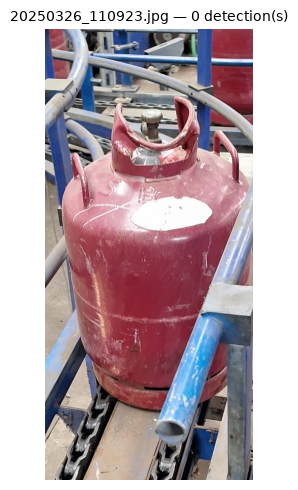

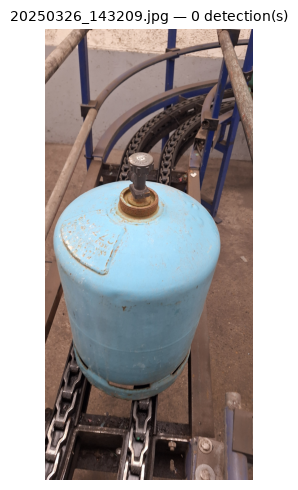


Saved 5 annotated images to results\gas_bottle_baseline\annotated
  - annotated_20250326_112218.jpg
  - annotated_20250326_130133.jpg
  - annotated_20250326_130204.jpg
  - annotated_20250326_110923.jpg
  - annotated_20250326_143209.jpg


In [12]:
def annotate(img_path, model, conf=0.25):
    res = model.predict(
        source=str(img_path),
        conf=conf,
        device=device,
        verbose=False,
    )[0]
    annotated = res.plot()
    n = 0 if res.boxes is None else len(res.boxes)
    labels = sorted(set(model.names[int(c)] for c in res.boxes.cls.cpu().numpy())) if n else []
    return annotated, n, labels


with_det = df[df["n_detections"] > 0]["image"].tolist()
without_det = df[df["n_detections"] == 0]["image"].tolist()

images_to_show = with_det[:3] + without_det[:2]
name_to_path = {p.name: p for p in image_paths}

saved_paths = []

for img_name in images_to_show:
    img_path = name_to_path[img_name]
    annotated, n, labels = annotate(img_path, model, conf=0.25)

    out_path = ANNOTATED_DIR / f"annotated_{img_path.name}"
    cv2.imwrite(str(out_path), annotated)
    saved_paths.append(out_path)

    rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(rgb)
    ax.axis("off")
    title = f"{img_name} — {n} detection(s)"
    if labels:
        title += f" — {', '.join(labels)}"
    ax.set_title(title, fontsize=10)
    plt.tight_layout()
    plt.show()

print(f"\nSaved {len(saved_paths)} annotated images to {ANNOTATED_DIR.relative_to(ROOT)}")
for p in saved_paths:
    print(f"  - {p.name}")

### Summary

In [13]:
summary = {
    "Model": "YOLO11n (pretrained on COCO)",
    "Model size": "nano",
    "Input images": total_images,
    "Image source": str(IMAGE_DIR.relative_to(ROOT)),
    "Confidence threshold": 0.25,
    "Images with >=1 detection": images_with_detections,
    "Percentage with detection": f"{images_with_detections/total_images*100:.1f}%",
    "Total detections": total_detections,
    "Explicit cylinder class in model": has_cylinder_class,
    "Top detected classes": dict(class_counts.most_common(5)),
    "Annotated images saved": len(saved_paths),
    "Annotated output folder": str(ANNOTATED_DIR.relative_to(ROOT)),
    "Device used": str(device),
}

print("=" * 60)
print("REPORT SUMMARY — BASELINE DETECTION")
print("=" * 60)
for k, v in summary.items():
    print(f"{k:35s}: {v}")
print("=" * 60)

REPORT SUMMARY — BASELINE DETECTION
Model                              : YOLO11n (pretrained on COCO)
Model size                         : nano
Input images                       : 321
Image source                       : data\all_images
Confidence threshold               : 0.25
Images with >=1 detection          : 247
Percentage with detection          : 76.9%
Total detections                   : 454
Explicit cylinder class in model   : False
Top detected classes               : {'vase': 128, 'person': 97, 'chair': 32, 'bottle': 30, 'fire hydrant': 18}
Annotated images saved             : 5
Annotated output folder            : results\gas_bottle_baseline\annotated
Device used                        : cpu
